In [83]:
import sys
from types import MethodType

sys.path.append(r"C:\Users\admin\Documents\GitHub\THA\lib")
from pathlib import Path
import argparse

import numpy as np
import torch
import torch.utils
import torch.utils.data
import wandb
import lightning.pytorch as pl
from lightning.pytorch.loggers.wandb import WandbLogger
from lightning.pytorch.callbacks import LearningRateMonitor
from scipy.integrate import trapezoid

torch.set_default_dtype(torch.float64)

from nRTD.rtd_fitting import RTDModule, RTDDataModule
#from SweepRunner import Sweeper
import matplotlib.pyplot as plt

plt.style.use("ICIWstyle")

# 1 - data import

In [84]:
# npz datein von n_dot und t

path_data_capillary = r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_001\data\FBA-E-18032025_300ml-min_Analytik_MS.npz"
path_data_reactor_inlet = r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\B_vorreaktor_2barabs\nRTD_ptk_vorreaktor_nocat_25°C_1bar_reactor250mlmin_matrix0mlmin.npz"
path_data_reactor_outlet = r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\C_nachreaktor_2barabs\nRTD_ptk_nachreaktor_nocat_150°C_aequi_1bar_reactor250mlmin_matrix0mlmin.npz"
path_data_total_system = r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\D_gessys_2barabs\nRTD_ptk_gessys_nocat_150°C_aequi_1bar_reactor250mlmin_matrix0mlmin.npz"



path_data_capillary_old = r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_001\data\FBA-E-18032025_300ml-min_Analytik_MS.npz"
path_data_reactor_inlet_old = r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_002\data\MGA-E-11032025_30ml-min_1atm_ReactorInlet_MS.npz"
path_data_reactor_outlet_old =r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_003\data\MGA-E-11032025_30ml-min_1atm_ReactorOutlet_MS.npz"
path_data_total_system_old = r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_004\data\MGA-E-10032025_30ml-min_1atm_TotalSystem.npz"

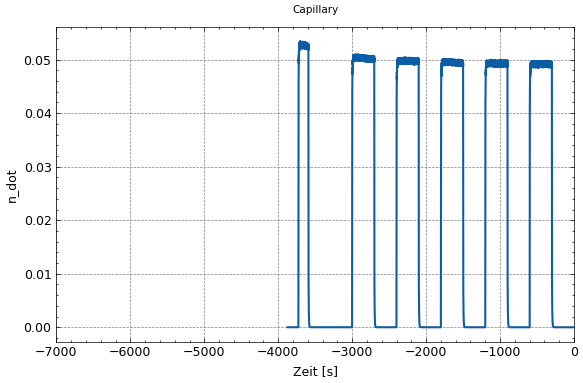

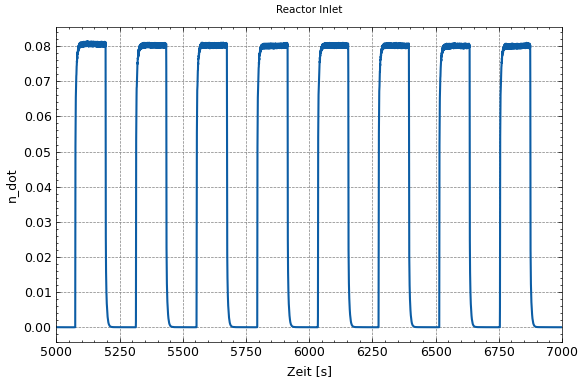

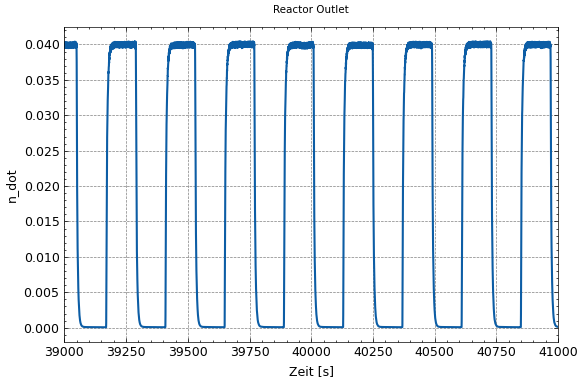

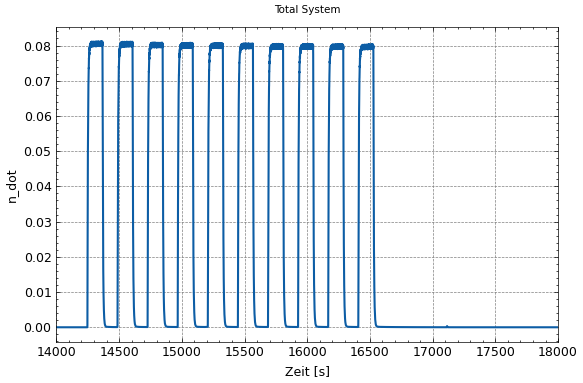

In [85]:
# Dateien laden
data_capillary = np.load(path_data_capillary_old)
data_reactor_inlet = np.load(path_data_reactor_inlet)
data_reactor_outlet = np.load(path_data_reactor_outlet)
data_total_system = np.load(path_data_total_system)

datasets = [
    ("Capillary", data_capillary),
    ("Reactor Inlet", data_reactor_inlet),
    ("Reactor Outlet", data_reactor_outlet),
    ("Total System", data_total_system),
]

x_limits = {
    "Capillary": (-7000, 0),
    "Reactor Inlet": (5000, 7000),
    "Reactor Outlet": (39000, 41000),
    "Total System": (14000, 18000),
}

for title, data in datasets:

    x_min, x_max = x_limits[title]

    mask = (
        (data["time_delta"] >= x_min)
        & (data["time_delta"] <= x_max)
    )

    plt.figure(figsize=(6, 4))

    plt.plot(
        data["time_delta"][mask],
        data["n_dot"][0, mask],
        lw=1.5
    )

    plt.title(title)
    plt.xlabel("Zeit [s]")
    plt.ylabel("n_dot")
    plt.xlim(x_min, x_max)
    plt.grid(True)
    plt.tight_layout()

    plt.show()

# 2 - plotting

In [86]:
def log_plots(data_module: RTDDataModule, model: RTDModule, index=0, Es_to_plot=[0]):
    pred_y, pred_t = model(data_module.x, data_module.t_in)
    pred_t = pred_t.detach().numpy().squeeze()
    pred_y = pred_y.detach().numpy().squeeze()

    fig = plt.figure()
    index = 0
    plt.plot(
        data_module.t_in[index],
        data_module.x[index].squeeze(),
        ls="--",
    )
    plt.plot(
        data_module.t_in[index + 2],
        data_module.x[index + 2].squeeze(),
        ls="--",
    )
    plt.plot(
        data_module.t_out[index],
        data_module.y[index].squeeze(),
        "o",
        c="C0",
        markersize=0.5,
    )
    plt.plot(
        data_module.t_out[index + 2],
        data_module.y[index + 2].squeeze(),
        "o",
        c="C1",
        markersize=0.5,
    )
    plt.plot(
        data_module.t_in[index + 1],
        data_module.x[index + 1].squeeze(),
        ls="--",
        c="C2",
    )
    plt.plot(
        data_module.t_in[index + 3],
        data_module.x[index + 3].squeeze(),
        ls="--",
        c="C3",
    )
    plt.plot(
        data_module.t_out[index + 1],
        data_module.y[index + 1].squeeze(),
        "o",
        c="C2",
        markersize=0.5,
    )
    plt.plot(
        data_module.t_out[index + 3],
        data_module.y[index + 3].squeeze(),
        "o",
        c="C3",
        markersize=0.5,
    )

    plt.plot(pred_t[index, :], pred_y[index, :], c="C0")
    plt.plot(pred_t[index + 2].squeeze(), pred_y[index + 2].squeeze(), c="C1")
    plt.plot(pred_t[index + 1, :], pred_y[index + 1, :], c="C2")
    plt.plot(pred_t[index + 3].squeeze(), pred_y[index + 3].squeeze(), c="C3")
    plt.xlabel("t / s")
    plt.ylabel("x / 1")
    plt.twinx()
    ax = plt.gca()
    plt.ylabel("$E \;/\; s^{-1}$")
    my_colors = ["darkmagenta", "goldenrod", "firebrick", "darkcyan"]
    for E_index in Es_to_plot:
        ax.plot(
            model.net.conv_layers[E_index].t_kernel.detach().numpy(),
            model.net.E[E_index],
            color=my_colors[E_index],
        )
    wandb.log({f"RTD_Plot_img": wandb.Image(fig)})
    wandb.log({f"RTD_Plot_fig": fig})

<>:67: SyntaxWarning:

invalid escape sequence '\;'

<>:67: SyntaxWarning:

invalid escape sequence '\;'

C:\Users\admin\AppData\Local\Temp\ipykernel_8648\3345537236.py:67: SyntaxWarning:

invalid escape sequence '\;'



# 3 - constans

In [87]:
# givens
t_out = (0.0, 120.0)
n_out = int(4 * (t_out[1] - t_out[0]) + 1)
delta_t_out = (t_out[1] - t_out[0]) / (n_out - 1)

# the capillary times

switching_periods = np.array(
    [
        5 * 60 + 0.03,
        5 * 60 + 0.27,
        5 * 60 + 0.27,
        5 * 60 + 0.28,
        5 * 60 + 0.18,
        5 * 60 + 0.26,
        5 * 60 + 0.33,
        5 * 60 + 0.27,
        5 * 60 + 0.18,
        5 * 60 + 0.05,
    ]
)

t_offset_capillary = 0 
t_offset_reactor_inlet = 5790 -5
t_offset_reactor_outlet = 39880 -5
t_offset_ges_system = 15443 -20 
# the piping times
t_halfperiod = t_out[1] - t_out[0]


switching_times_cap = np.flip(np.cumsum(-switching_periods))
switching_times_cap = np.append(switching_times_cap, 0) - 1
# )  # leave enough time for the step


# automated_switching_times = np.full((20,), t_halfperiod)
# switching_times_reac_inlet = np.insert(automated_switching_times, 0, 7.4 - 1.0)
# switching_times_reac_inlet = np.cumsum(switching_times_reac_inlet)
# switching_times_reac_outlet = np.insert(automated_switching_times, 0, 7.5 - 0.25 - 1.0)
# switching_times_reac_outlet = np.cumsum(switching_times_reac_outlet)
# switching_times_total_system = np.insert(automated_switching_times, 0, 7.5 - 0.5 - 1.0)
# switching_times_total_system = np.cumsum(switching_times_total_system)

automated_switching_times = np.full((10,), t_halfperiod)
# switching_times_cap = np.insert(automated_switching_times, 0, t_offset_capillary)
# switching_times_cap = np.cumsum(switching_times_cap)
switching_times_reac_inlet = np.insert(automated_switching_times, 0, t_offset_reactor_inlet)
switching_times_reac_inlet = np.cumsum(switching_times_reac_inlet)
switching_times_reac_outlet = np.insert(automated_switching_times, 0, t_offset_reactor_outlet)
switching_times_reac_outlet = np.cumsum(switching_times_reac_outlet)
switching_times_total_system = np.insert(automated_switching_times, 0, t_offset_ges_system)
switching_times_total_system = np.cumsum(switching_times_total_system)

# t_kernels = [
#     (0.0, 30.0),  # piping to reactor inlet
#     (0.0, 40.0),  # reactor
#     (0.0, 15.0),  # piping after reactor outlet
#     (0.0, 30.0),  # capillary
# ]

t_kernels = [
    (0.0, 25.0),  # piping to reactor inlet
    (0.0, 40.0),  # reactor
    (0.0, 25.0),  # piping after reactor outlet
    (0.0, 20.0),  # capillary
]

# n_kernels = list(
#     map(
#         lambda t_kernel: int(((t_kernel[1] - t_kernel[0]) / delta_t_out) + 1), t_kernels
#     )
# )

n_kernels = list(
    map(
        lambda t_kernel: int(((t_kernel[1] - t_kernel[0]) / delta_t_out) + 1), t_kernels
    )
)

t_in = (0, t_out[1] - sum([t_kernel[1] for t_kernel in t_kernels]))
n_in = int(((t_in[1] - t_in[0]) / delta_t_out) + 1)



print("t_in:",t_in)
print("t_out:",t_out)
print("n_in:",n_in)
print("n_out:",n_out)

print("switching_times_cap:",switching_times_cap)

intervals = [
    (switching_times_cap[i], switching_times_cap[i + 1])
    for i in range(len(switching_times_cap) - 1)
]
print(intervals)


with np.load(path_data_capillary) as data:
    times_raw = data["time_delta"]
print("switching_times_cap[0]:", switching_times_cap[0], " gültiger Bereich:", times_raw.min(), "-", times_raw.max())

t_in: (0, 10.0)
t_out: (0.0, 120.0)
n_in: 41
n_out: 481
switching_times_cap: [-3.00312e+03 -2.70307e+03 -2.40289e+03 -2.10262e+03 -1.80229e+03
 -1.50203e+03 -1.20185e+03 -9.01570e+02 -6.01300e+02 -3.01030e+02
 -1.00000e+00]
[(np.float64(-3003.12), np.float64(-2703.0699999999997)), (np.float64(-2703.0699999999997), np.float64(-2402.89)), (np.float64(-2402.89), np.float64(-2102.62)), (np.float64(-2102.62), np.float64(-1802.29)), (np.float64(-1802.29), np.float64(-1502.03)), (np.float64(-1502.03), np.float64(-1201.85)), (np.float64(-1201.85), np.float64(-901.5699999999999)), (np.float64(-901.5699999999999), np.float64(-601.3)), (np.float64(-601.3), np.float64(-301.03)), (np.float64(-301.03), np.float64(-1.0))]
switching_times_cap[0]: -3003.12  gültiger Bereich: -3874.175 - 0.0


# 4 - WnB initialization

In [88]:
wandb.init(project="THB_nRTD", entity="ice_ulm")

epoch,▁▁▄▅▅▇▇▇██▂▃▄▄▅▆▆▆▇▇▇█▁▂▃▄▄▅▆▆▇▇█▁▁▁▂▂▃▅
lr-Adam,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,▁▁▁▁▁▁▁▁█▃▁▁▁▁▁▁▂▂▂▁▁▁▁▁▁▁▁▁█▃▂▂▁▁▁▁▁▁▁▁
trainer/global_step,▄▅▅▅▆█▃▄▄▄▅██▁▃▄▄▄▄▅▆▇▇▇▇█▁▁▂▂▃▃▃▃▃▅▅▇██
epoch,4999
lr-Adam,0.004
train/loss,0.0
trainer/global_step,4999


# 5 - DataModules 

In [89]:
data_cap = RTDDataModule(
    batch_size=32,
    data_file=Path(
        path_data_capillary_old
    ),
    switching_times=switching_times_cap,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)


def patch_setup(self, stage: str):
    import scipy

    if self.is_setup:
        return False

    print("Setup")
    # load the raw data from disc
    with np.load(self.data_file) as data:
        n_dot = data["n_dot"]
        times = data["time_delta"]

    # interpolate the data to the measured time scale
    interp = scipy.interpolate.interp1d(
        times,
        n_dot,
        kind="linear",
        fill_value="extrapolate",
    )
    # calculate the time scales for the input and output data
    t_in = np.linspace(
        self.t_range_in[0],
        self.t_range_in[1],
        self.n_in,
    )
    t_out = np.linspace(
        self.t_range_out[0],
        self.t_range_out[1],
        self.n_out,
    )
    delta_t = (self.t_range_out[1] - self.t_range_out[0]) / (self.n_out - 1)

    # for each interval in ther switching periods, interpolate the data on that interval
    for i, interval in enumerate(self.intervals):
        # check if the period is even or odd
        even_period = i % 2 == 0
        # begin of interpolation
        interp_begin = interval[0] + self.t_range_out[0]
        # end of interpolation
        interp_end = interp_begin + self.t_range_out[-1]
        # auxilliray time scale for the interpolation
        # 15 seconds of the end of each signal will be repeated to pad out the signal to 2 min
        interp_aux = interp_begin + 30
        # available time scale for interpolation
        #  hard coded 15 seconds
        interp_avail = interp_begin + 45

        t_interp = np.linspace(
            interp_begin,
            interp_end,
            self.n_out,
        )
        n_avail = int((interp_avail - interp_begin) / delta_t + 1)
        t_avail = np.linspace(
            interp_begin,
            interp_avail,
            n_avail,
        )
        n_aux = int((interp_avail - interp_aux) / delta_t)
        t_aux = np.linspace(
            interp_aux,
            interp_avail,
            n_aux,
        )

        # we only care about Ar and He as tracers
        n_dot_interp_avail = interp(t_avail)[
            [0, 1]
        ]  # shape is (2, n_out) that is two valid samples
        n_dot_interp_aux = interp(t_aux)[[0, 1]]
        n_dot_interp_aux = np.tile(n_dot_interp_aux, (1, 5))
        n_dot_interp = np.concatenate([n_dot_interp_avail, n_dot_interp_aux], axis=1)

        # get the respective 0 and 1 values for the switch
        if even_period:
            try:
                even_steady_state_values = np.append(
                    even_steady_state_values, n_dot_interp[None, :, [0, -1]], axis=0
                )
            except NameError:
                even_steady_state_values = n_dot_interp[None, :, [0, -1]]
        else:
            try:
                odd_steady_state_values = np.append(
                    odd_steady_state_values, n_dot_interp[None, :, [0, -1]], axis=0
                )
            except NameError:
                odd_steady_state_values = n_dot_interp[None, :, [0, -1]]

        # stack the interpolated data
        try:
            y = np.vstack((y, n_dot_interp))
        except NameError:
            y = n_dot_interp

    #  take the mean over all samples to get somewhat reliable steady state values
    even_steady_state_values = even_steady_state_values.mean(
        axis=0
    )  # shape (2,2) first index is species, second index is the steady state
    odd_steady_state_values = odd_steady_state_values.mean(axis=0)

    # claculate the step functions for each interval
    for i, interval in enumerate(self.intervals):
        # check if the period is even or odd
        even_period = i % 2 == 0

        if even_period:
            steady_state_values = even_steady_state_values
        else:
            steady_state_values = odd_steady_state_values

        n_dot_in = np.zeros((2, self.n_in))
        n_dot_in[0, :] = np.where(
            t_in < self.switch_delay,
            steady_state_values[0, 0],
            steady_state_values[0, 1],
        )
        n_dot_in[1, :] = np.where(
            t_in < self.switch_delay,
            steady_state_values[1, 0],
            steady_state_values[1, 1],
        )

        # stack the step functions
        try:
            x = np.vstack((x, n_dot_in))
        except NameError:
            x = n_dot_in
    self.y = torch.Tensor(y)[:, None, :]
    self.x = torch.tensor(x)[:, None, :]
    t_in = torch.tensor(t_in)
    t_out = torch.tensor(t_out)
    self.t_in = torch.tile(t_in, (2 * len(self.intervals), 1))
    self.t_out = torch.tile(t_out, (2 * len(self.intervals), 1))
    self.initialize_data_sets()
    self.is_setup = True
    return True

# folgendes in Alex code aber nicht bei hannes (die 3 zeilen vorher aber bei hannes)
    # self.data_set = torch.utils.data.TensorDataset(self.x, self.t_in, self.y)
    # self.train_set, self.test_set = torch.utils.data.random_split(
    #     self.data_set,
    #     [
    #         int(0.8 * len(self.data_set)),
    #         len(self.data_set) - int(0.8 * len(self.data_set)),
    #     ],
    # )


data_cap.setup = MethodType(patch_setup, data_cap)
# data_cap.setup("fit")
# data_cap.x = data_cap.x[1::4, ...]
# data_cap.t_in = data_cap.t_in[1::4, ...]
# data_cap.y = data_cap.y[1::4, ...]
# data_cap.initialize_data_sets()


In [90]:
data_reac_inlet = RTDDataModule(
    batch_size=32,
    data_file=Path(
        path_data_reactor_inlet
    ),
    switching_times=switching_times_reac_inlet,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)
# data_reac_inlet.setup("fit")
# data_reac_inlet.x = data_reac_inlet.x[1::4, ...]
# data_reac_inlet.t_in = data_reac_inlet.t_in[1::4, ...]
# data_reac_inlet.y = data_reac_inlet.y[1::4, ...]
# data_reac_inlet.initialize_data_sets()

In [91]:
data_reac_outlet = RTDDataModule(
    batch_size=32,
    data_file=Path(
        path_data_reactor_outlet
    ),
    switching_times=switching_times_reac_outlet,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)
# data_reac_outlet.setup("fit")
# data_reac_outlet.x = data_reac_outlet.x[1::4, ...]
# data_reac_outlet.t_in = data_reac_outlet.t_in[1::4, ...]
# data_reac_outlet.y = data_reac_outlet.y[1::4, ...]
# data_reac_outlet.initialize_data_sets()

In [92]:
data_total_system = RTDDataModule(
    batch_size=32,
    data_file=Path(
        path_data_total_system
    ),
    switching_times=switching_times_total_system,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)
# data_total_system.setup("fit")
# data_total_system.x = data_total_system.x[1::4, ...]
# data_total_system.t_in = data_total_system.t_in[1::4, ...]
# data_total_system.y = data_total_system.y[1::4, ...]
# data_total_system.initialize_data_sets()

# 6 - plots Teilschritte

## capillary

In [93]:
data_cap.setup("fit")
data_cap.x[0]
print(data_cap.x.shape)

Setup
torch.Size([20, 1, 41])


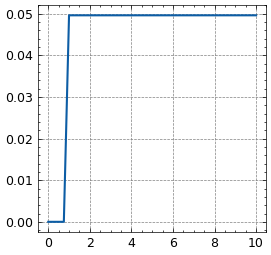

In [94]:
%matplotlib inline
plt.plot(data_cap.t_in[0,:], data_cap.x[0,0,:])
plt.show()
plt.close()

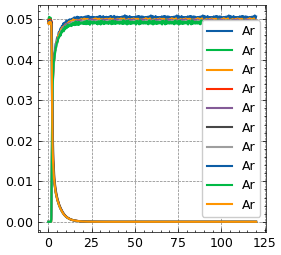

In [95]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if i %2==0:
        plt.plot(data_cap.t_out[i, :], data_cap.y[i, 0, ...], label="Ar")
plt.legend()
plt.show()
plt.close()

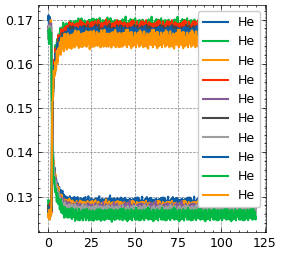

In [96]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if not i %2==0:
        plt.plot(data_cap.t_out[i, :], data_cap.y[i, 0, ...], label="He")
plt.legend()
plt.show()
plt.close()

## reactor inlet

In [97]:
data_reac_inlet.setup("fit")
data_reac_inlet.x[0]
print(data_reac_inlet.x.shape)

torch.Size([20, 1, 41])


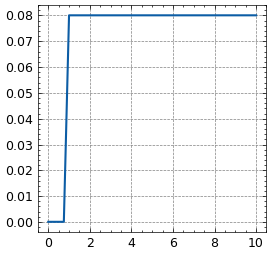

In [98]:
%matplotlib inline
plt.plot(data_reac_inlet.t_in[0,:], data_reac_inlet.x[0,0,:]) # switch delay hochsetzen
plt.show()
plt.close()

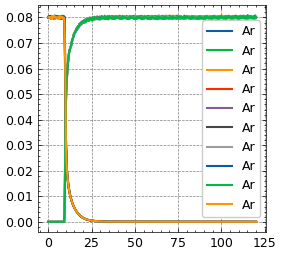

In [99]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if i %2==0:
        plt.plot(data_reac_inlet.t_out[i, :], data_reac_inlet.y[i, 0, ...], label="Ar")
plt.legend()
plt.show()
plt.close()

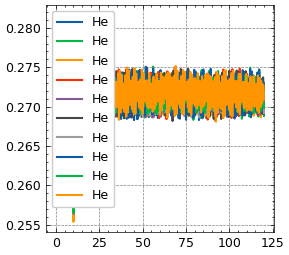

In [100]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if not i %2==0:
        plt.plot(data_reac_inlet.t_out[i, :], data_reac_inlet.y[i, 0, ...], label="He")
plt.legend()
plt.show()
plt.close()

## reactor outlet

In [101]:
data_reac_outlet.setup("fit")
data_reac_outlet.x[0]
print(data_reac_outlet.x.shape)

torch.Size([20, 1, 41])


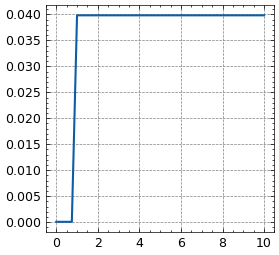

In [102]:
%matplotlib inline
plt.plot(data_reac_outlet.t_in[0,:], data_reac_outlet.x[0,0,:])
plt.show()
plt.close()

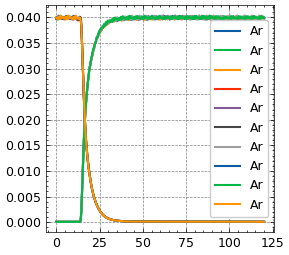

In [103]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if i %2==0:
        plt.plot(data_reac_outlet.t_out[i, :], data_reac_outlet.y[i, 0, ...], label="Ar")
plt.legend()
plt.show()
plt.close()

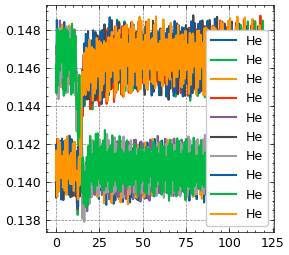

In [104]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if not i %2==0:
        plt.plot(data_reac_outlet.t_out[i, :], data_reac_outlet.y[i, 0, ...], label="He")
plt.legend()
plt.show()
plt.close()

## total system

In [105]:
data_total_system.setup("fit")
data_total_system.x[0]
print(data_total_system.x.shape)

torch.Size([20, 1, 41])


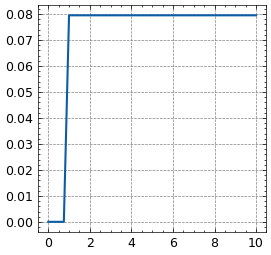

torch.Size([20, 1, 41])


In [106]:
%matplotlib inline
plt.plot(data_total_system.t_in[0,:], data_total_system.x[0,0,:])
plt.show()
plt.close()

print(data_total_system.x.shape)

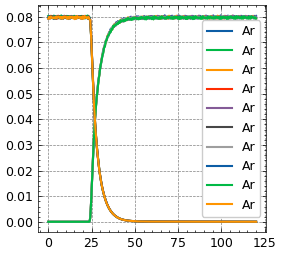

In [107]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if i %2==0:
        plt.plot(data_total_system.t_out[i, :], data_total_system.y[i, 0, ...], label="Ar")
plt.legend()
plt.show()
plt.close()

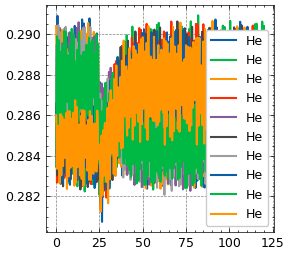

In [108]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if not i %2==0:
        plt.plot(data_total_system.t_out[i, :], data_total_system.y[i, 0, ...], label="He")
plt.legend()
plt.show()
plt.close()

# 7 - model setup & trainier initialization

In [109]:
model = RTDModule(
    kernel_sizes=n_kernels,
    kernel_times=t_kernels,
    learning_rate=4e-3,
    use_scheduler=False,
    scheduler_kwargs={"factor": 0.6, "patience": 2000},
)

my_logger = WandbLogger(log_model=True)
lr_callback = LearningRateMonitor()

# max_epochs = 20_000
max_epochs = 20_000

trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=max_epochs,
    enable_progress_bar=True,
    logger=my_logger,
    callbacks=[lr_callback],
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


# 8 - Training

In [110]:
for conv_layer in model.net.conv_layers:
    conv_layer.set_to_direct_response()
    conv_layer.freeze()

In [111]:
model.net.conv_layers[3].unfreeze()
trainer.fit(model, data_cap)

log_plots(
    data_module=data_cap,
    model=model,
    index=0,
    Es_to_plot=[3],
)


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: PossibleUserWarning:

You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\lightning\pytorch\loggers\wandb.py:400: UserWarning:

There is a wandb run already in progress and newly created instances of `WandbLogger` will reuse this run. If this is not desired, call `wandb.finish()` before instantiating `WandbLogger`.



┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ RTDNet │    444 │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 81                                                                                               
Non-trainable params: 363                                                                                          
Total params: 444                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\lightning\pytorch\utilities\_pytree.py:21: FutureWarning:

`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: PossibleUserWarning:

The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=5` in the `DataLoader` to improve performance.

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\lightning\pytorch\loops\fit_loop.py:317: PossibleUserWarning:

The number of training batches (1) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.



`Trainer.fit` stopped: `max_epochs=20000` reached.


C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\plotly\matplotlylib\renderer.py:600: UserWarning:

Looks like the annotation(s) you are trying 
to draw lies/lay outside the given figure size.

Therefore, the resulting Plotly figure may not be 
large enough to view the full text. To adjust 
the size of the figure, use the 'width' and 
'height' keys in the Layout object. Alternatively,
use the Margin object to adjust the figure's margins.



In [112]:
model.net.conv_layers[3].freeze()
model.net.conv_layers[0].unfreeze()
model.configure_optimizers()
trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=max_epochs,
    enable_progress_bar=True,
    logger=my_logger,
    callbacks=[lr_callback],
)
trainer.fit(model, data_reac_inlet)

log_plots(
    data_module=data_reac_inlet,
    model=model,
    index=0,
    Es_to_plot=[0, 3],
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\lightning\pytorch\callbacks\model_checkpoint.py:881: UserWarning:

Checkpoint directory .\lightning_logs\r0qvi2ao\checkpoints exists and is not empty.



┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ RTDNet │    444 │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 101                                                                                              
Non-trainable params: 343                                                                                          
Total params: 444                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=20000` reached.


In [113]:
model.net.conv_layers[0].freeze()
model.net.conv_layers[1].unfreeze()
model.configure_optimizers()
trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=max_epochs,
    enable_progress_bar=True,
    logger=my_logger,
    callbacks=[lr_callback],
)
trainer.fit(model, data_reac_outlet)

log_plots(
    data_module=data_reac_outlet,
    model=model,
    index=0,
    Es_to_plot=[0, 1, 3],
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ RTDNet │    444 │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 161                                                                                              
Non-trainable params: 283                                                                                          
Total params: 444                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=20000` reached.


In [114]:
model.net.conv_layers[1].freeze()
model.net.conv_layers[2].unfreeze()
model.configure_optimizers()
trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=max_epochs,
    enable_progress_bar=True,
    logger=my_logger,
    callbacks=[lr_callback],
)
trainer.fit(model, data_total_system)

log_plots(
    data_module=data_total_system,
    model=model,
    index=0,
    Es_to_plot=[0, 1, 2, 3],
)

plt.show()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ RTDNet │    444 │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 101                                                                                              
Non-trainable params: 343                                                                                          
Total params: 444                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=20000` reached.


# 9 - Teilplots

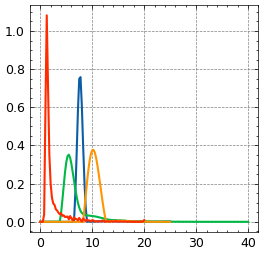

In [115]:
Es = []
ts = []
delta_ts = []

for i in np.arange(0,4):#
    Es.append(model.net.E[i].detach().numpy())
    ts.append(model.net.conv_layers[i].t_kernel.detach().numpy())
    delta_ts.append(delta_ts.append(model.net.delta_t[i].item()))
    plt.plot(ts[i], Es[i])

--- Validierung: Flächenberechnung (Idealfall alle =1) ---
E_1: Fläche = 1.0058
E_2: Fläche = 0.9977
E_3: Fläche = 0.9974
E_4: Fläche = 0.9959


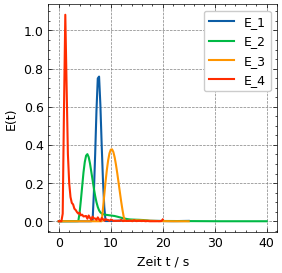

In [116]:
Es = []
ts = []

delta_ts = [] 

print("--- Validierung: Flächenberechnung (Idealfall alle =1) ---")

for i in np.arange(0, 4):
    # Daten extrahieren
    E_numpy = model.net.E[i].detach().numpy()
    t_numpy = model.net.conv_layers[i].t_kernel.detach().numpy()
    
    Es.append(E_numpy)
    ts.append(t_numpy)
    delta_ts.append(model.net.delta_t[i].item())
    
    # Flächenberechnung via Trapezregel
    flaeche = trapezoid(E_numpy, x=t_numpy)
    
    print(f"E_{i+1}: Fläche = {flaeche:.4f}")
    plt.plot(t_numpy, E_numpy, label=f'E_{i+1}')

plt.xlabel('Zeit t / s')
plt.ylabel('E(t)')
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

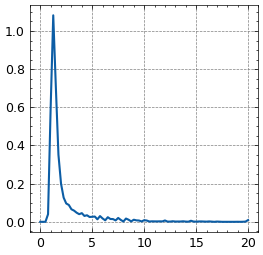

In [117]:
# capillary
plt.plot(ts[3], Es[3])

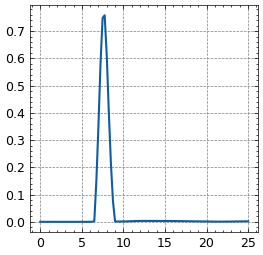

In [118]:
# reactor inlet
plt.plot(ts[0], Es[0])

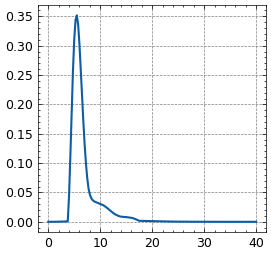

In [119]:
# reactor outlet
plt.plot(ts[1], Es[1])

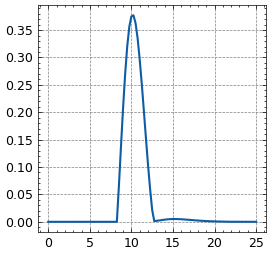

In [120]:
# gesamt system
plt.plot(ts[2], Es[2])

In [121]:
# from datetime import datetime
# d=datetime.now().strftime("%Y-%m-%d_%H%M%S")

# data ={'ts':ts,
#         'Es':Es,
#         'delta_ts':delta_ts,

#         't_in cap':data_cap.t_in.detach().numpy(),
#         'x_in cap':data_cap.x.detach().numpy(),
#         't_out cap':data_cap.t_out.detach().numpy(),
#         'x_out cap':data_cap.y.detach().numpy(),

#         't_in inlet':data_reac_inlet.t_in.detach().numpy(),
#         'x_in inlet':data_reac_inlet.x.detach().numpy(),
#         't_out inlet':data_reac_inlet.t_out.detach().numpy(),
#         'x_out inlet':data_reac_inlet.y.detach().numpy(),

#         't_in outlet':data_reac_inlet.t_in.detach().numpy(),
#         'x_in outlet':data_reac_inlet.x.detach().numpy(),
#         't_out outlet':data_reac_inlet.t_out.detach().numpy(),
#         'x_out outlet':data_reac_inlet.y.detach().numpy(),

#         't_in total':data_total_system.t_in.detach().numpy(),
#         'x_in total':data_total_system.x.detach().numpy(),
#         't_out total':data_total_system.t_out.detach().numpy(),
#         'x_out total':data_total_system.y.detach().numpy(),}

# np.save(f"Runs\Run_{d}_2bar_150grad_ohneMatrix.npy", data)

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:1307: RuntimeWarning:

divide by zero encountered in divide

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:1308: RuntimeWarning:

divide by zero encountered in divide

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:1309: RuntimeWarning:

divide by zero encountered in divide

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:1315: RuntimeWarning:

invalid value encountered in add



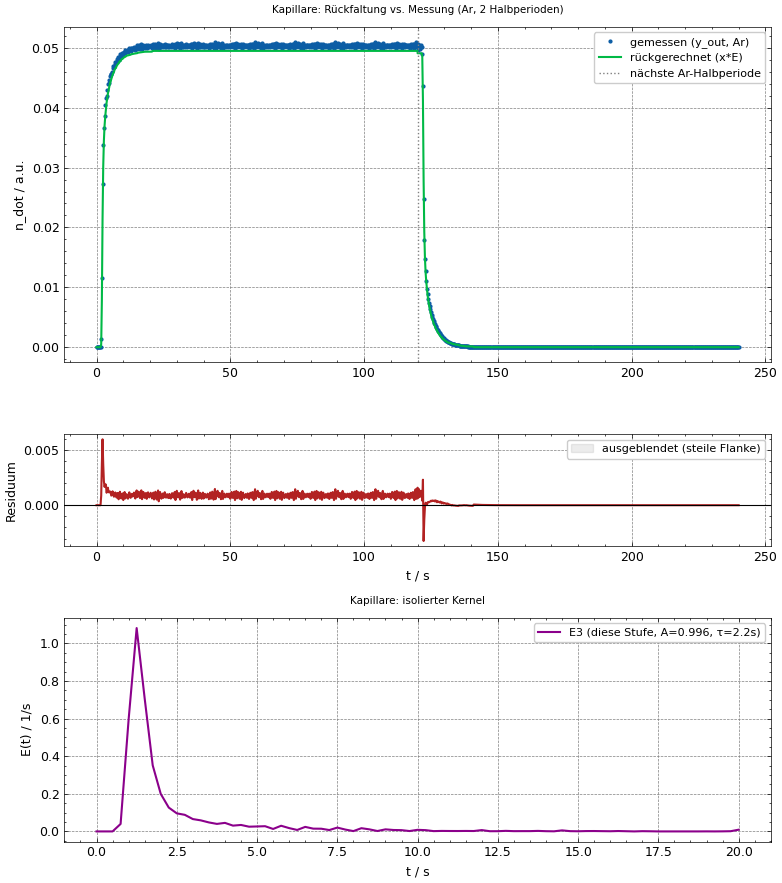

Kapillare (Ar-Zyklen 0/1): R² = 0.9991, RMSE = 0.0007269, NRMSE = 1.43%


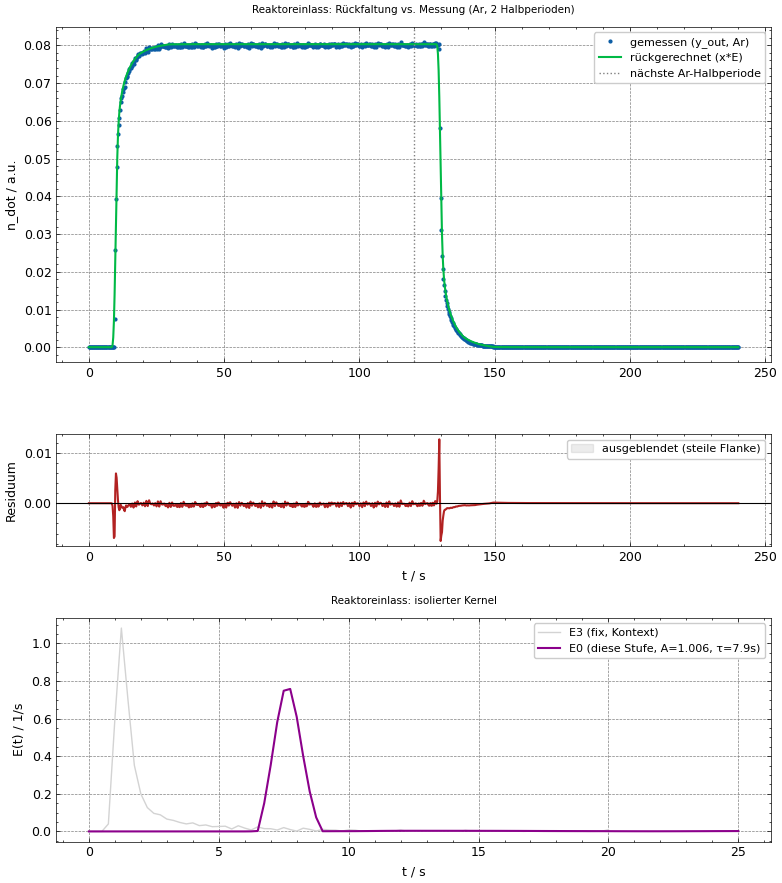

Reaktoreinlass (Ar-Zyklen 0/1): R² = 0.9996, RMSE = 0.0008175, NRMSE = 1.01%


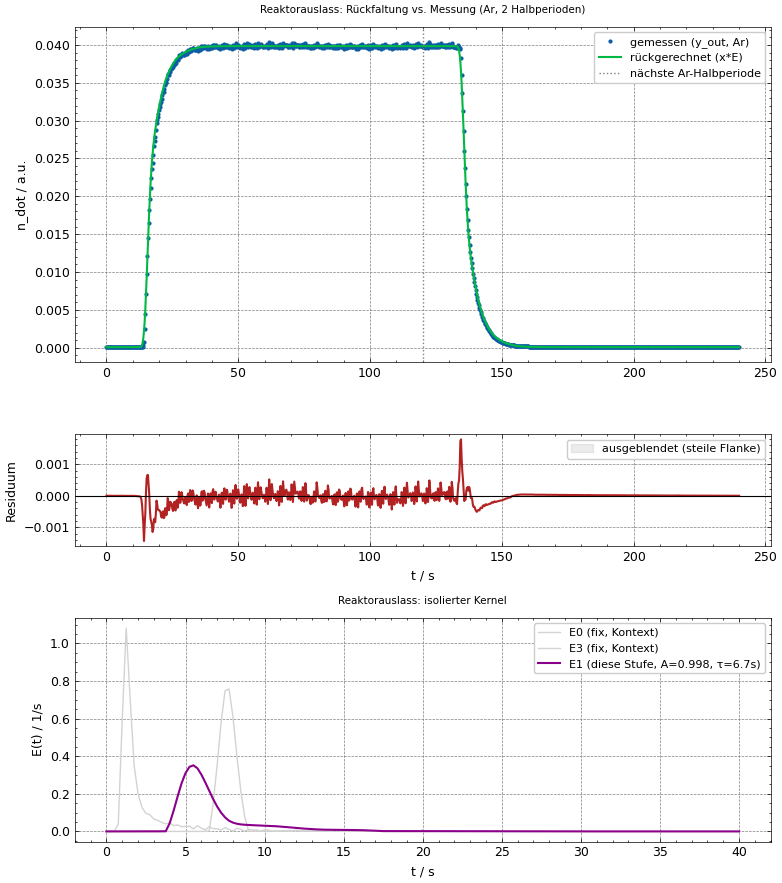

Reaktorauslass (Ar-Zyklen 0/1): R² = 0.9999, RMSE = 0.0002203, NRMSE = 0.55%


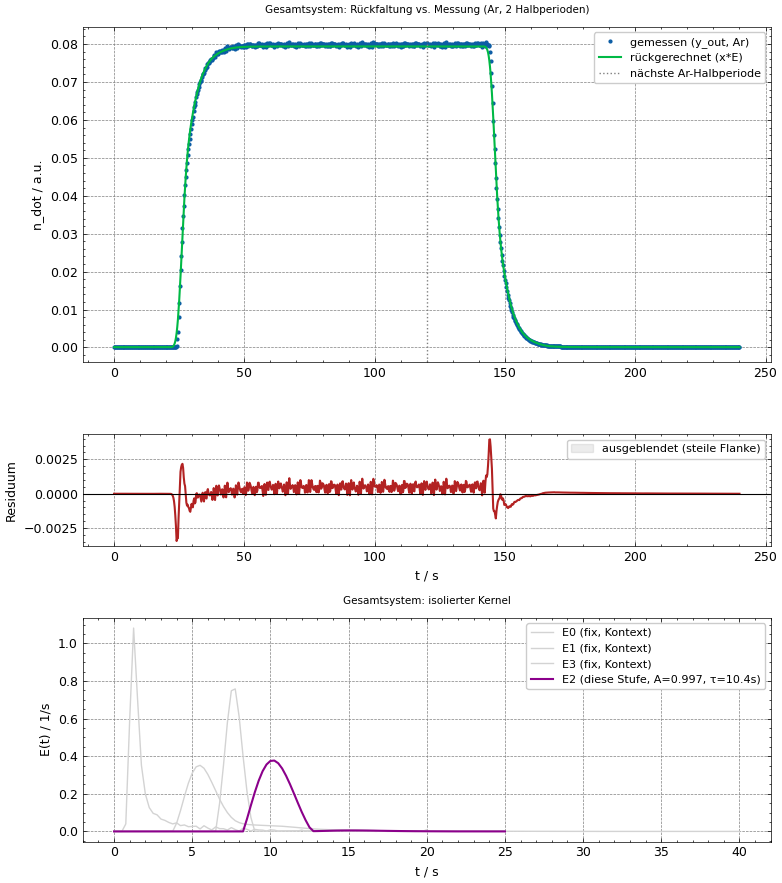

Gesamtsystem (Ar-Zyklen 0/1): R² = 0.9998, RMSE = 0.0005547, NRMSE = 0.69%

--- Zusammenfassung (nur Ar) ---
Kapillare: R² = 0.9991, RMSE = 0.0007269
Reaktoreinlass: R² = 0.9996, RMSE = 0.0008175
Reaktorauslass: R² = 0.9999, RMSE = 0.0002203
Gesamtsystem: R² = 0.9998, RMSE = 0.0005547


In [122]:
import copy

# ---------------------------------------------------------------
# 1) Hilfsfunktion: Modellkopie mit nur bestimmten aktiven Kernen
# ---------------------------------------------------------------
def isolate_layers(model, active_indices):
    """Kopie des Modells, bei der nur die Kerne mit Index in active_indices
    ihren gefitteten Zustand behalten; alle anderen werden auf
    direct_response (Identität) zurückgesetzt."""
    model_copy = copy.deepcopy(model)
    for i, conv_layer in enumerate(model_copy.net.conv_layers):
        if i not in active_indices:
            conv_layer.set_to_direct_response()
    return model_copy


# ---------------------------------------------------------------
# 2) Validierungsfunktion: Rekonstruktion (nur Ar, 2 Halbperioden)
#    + Residuum + isolierter E-Kernel dieser Stufe
# ---------------------------------------------------------------
def validate_reconstruction_period(data_module, model, name, period_index=0,
                                    new_kernel_index=None, context_kernel_indices=None,
                                    slope_percentile=95):
    with torch.no_grad():
        pred_y, pred_t = model(data_module.x, data_module.t_in)
    pred_y = pred_y.numpy().squeeze()
    pred_t = pred_t.numpy().squeeze()
    y_true = data_module.y.detach().numpy().squeeze()
    t_out = data_module.t_out.detach().numpy().squeeze()

    # zwei aufeinanderfolgende Ar-Halbperioden, He dazwischen wird übersprungen
    i0 = 4 * period_index
    i1 = i0 + 2
    t_half = t_out[i0, -1] - t_out[i0, 0]

    t_true_full = np.concatenate([t_out[i0], t_out[i1] + t_half])
    y_true_full = np.concatenate([y_true[i0], y_true[i1]])
    t_pred_full = np.concatenate([pred_t[i0], pred_t[i1] + t_half])
    y_pred_full = np.concatenate([pred_y[i0], pred_y[i1]])

    y_pred_interp = np.interp(t_true_full, t_pred_full, y_pred_full)
    residual = y_true_full - y_pred_interp

    dy_dt = np.gradient(y_true_full, t_true_full)
    slope_threshold = np.percentile(np.abs(dy_dt), slope_percentile)
    steep_mask = np.abs(dy_dt) > slope_threshold
    steep_mask = steep_mask | np.roll(steep_mask, 1) | np.roll(steep_mask, -1)
    valid_mask = ~steep_mask

    ss_res = np.sum(residual[valid_mask]**2)
    ss_tot = np.sum((y_true_full[valid_mask] - np.mean(y_true_full[valid_mask]))**2)
    r2 = 1 - ss_res / ss_tot
    rmse = np.sqrt(np.mean(residual[valid_mask]**2))
    nrmse = rmse / (y_true_full.max() - y_true_full.min())

    residual_display = residual.copy()
    residual_display[~valid_mask] = np.nan

    fig, axes = plt.subplots(3, 1, figsize=(8, 9),
                              gridspec_kw={"height_ratios": [3, 1, 2]})

    # Panel 1: Rekonstruktion vs. Messung
    axes[0].plot(t_true_full, y_true_full, "o", ms=2, label="gemessen (y_out, Ar)")
    axes[0].plot(t_pred_full, y_pred_full, "-", label="rückgerechnet (x*E)")
    axes[0].axvline(t_half, color="gray", ls=":", lw=1, label="nächste Ar-Halbperiode")
    axes[0].set_ylabel("n_dot / a.u.")
    axes[0].legend(fontsize=8)
    axes[0].set_title(f"{name}: Rückfaltung vs. Messung (Ar, 2 Halbperioden)")

    # Panel 2: Residuum
    axes[1].plot(t_true_full, residual_display, color="firebrick")
    axes[1].axhline(0, color="k", lw=0.8)
    axes[1].fill_between(t_true_full, np.nanmin(residual_display), np.nanmax(residual_display),
                          where=steep_mask, color="gray", alpha=0.15,
                          label="ausgeblendet (steile Flanke)")
    axes[1].set_ylabel("Residuum")
    axes[1].set_xlabel("t / s")
    axes[1].legend(fontsize=8)

    # Panel 3: isolierter E-Kernel dieser Stufe (+ Kontext-Kernel gefittet, fix)
    ax_k = axes[2]
    if context_kernel_indices:
        for ci in context_kernel_indices:
            E_c = model.net.E[ci].detach().numpy()
            t_c = model.net.conv_layers[ci].t_kernel.detach().numpy()
            ax_k.plot(t_c, E_c, color="lightgray", lw=1, label=f"E{ci} (fix, Kontext)")
    if new_kernel_index is not None:
        E_n = model.net.E[new_kernel_index].detach().numpy()
        t_n = model.net.conv_layers[new_kernel_index].t_kernel.detach().numpy()
        area = trapezoid(E_n, x=t_n)
        tau = trapezoid(t_n * E_n, x=t_n) / area
        ax_k.plot(t_n, E_n, color="darkmagenta", lw=1.5,
                  label=f"E{new_kernel_index} (diese Stufe, A={area:.3f}, τ={tau:.1f}s)")
    ax_k.set_xlabel("t / s")
    ax_k.set_ylabel("E(t) / 1/s")
    ax_k.set_title(f"{name}: isolierter Kernel")
    ax_k.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    print(f"{name} (Ar-Zyklen {period_index}/{period_index+1}): "
          f"R² = {r2:.4f}, RMSE = {rmse:.4g}, NRMSE = {nrmse:.2%}")
    return r2, rmse


# ---------------------------------------------------------------
# 3) Modelle mit korrekt isolierten Kernen (Fit-Reihenfolge:
#    E3 -> E0 -> E1 -> E2, siehe Zellen 39-43)
# ---------------------------------------------------------------
model_cap_only    = isolate_layers(model, [3])
model_inlet_only  = isolate_layers(model, [0, 3])
model_outlet_only = isolate_layers(model, [0, 1, 3])
# Gesamtsystem: unverändertes model (alle 4 Kerne aktiv)


# ---------------------------------------------------------------
# 4) Validierung aller vier Teilsysteme, jeweils mit isoliertem Kernel
# ---------------------------------------------------------------
results = {}
results["Kapillare"] = validate_reconstruction_period(
    data_cap, model_cap_only, "Kapillare",
    new_kernel_index=3, context_kernel_indices=None, period_index=0)

results["Reaktoreinlass"] = validate_reconstruction_period(
    data_reac_inlet, model_inlet_only, "Reaktoreinlass",
    new_kernel_index=0, context_kernel_indices=[3], period_index=0)

results["Reaktorauslass"] = validate_reconstruction_period(
    data_reac_outlet, model_outlet_only, "Reaktorauslass",
    new_kernel_index=1, context_kernel_indices=[0, 3], period_index=0)

results["Gesamtsystem"] = validate_reconstruction_period(
    data_total_system, model, "Gesamtsystem",
    new_kernel_index=2, context_kernel_indices=[0, 1, 3], period_index=0)

print("\n--- Zusammenfassung (nur Ar) ---")
for name, (r2, rmse) in results.items():
    print(f"{name}: R² = {r2:.4f}, RMSE = {rmse:.4g}")

In [123]:
from datetime import datetime
d = datetime.now().strftime("%Y-%m-%d_%H%M%S")

# ---------------------------------------------------------------
# Rückrechnung (Vorwärtsfaltung x*E) für alle 4 Teilsysteme,
# jeweils mit dem für diese Messposition korrekt isolierten Modell
# (siehe Trainingsreihenfolge Zellen 39-43):
#   Kapillare      -> nur E3
#   Reaktoreinlass -> E0 + E3
#   Reaktorauslass -> E0 + E1 + E3
#   Gesamtsystem   -> E0 + E1 + E2 + E3 (unverändertes model)
# ---------------------------------------------------------------
with torch.no_grad():
    pred_y_cap, pred_t_cap = model_cap_only(data_cap.x, data_cap.t_in)
    pred_y_inlet, pred_t_inlet = model_inlet_only(data_reac_inlet.x, data_reac_inlet.t_in)
    pred_y_outlet, pred_t_outlet = model_outlet_only(data_reac_outlet.x, data_reac_outlet.t_in)
    pred_y_total, pred_t_total = model(data_total_system.x, data_total_system.t_in)

data = {
    'ts': ts,
    'Es': Es,
    'delta_ts': delta_ts,

    # welcher Kernel-Index bei welcher Stufe neu gefittet wurde,
    # und welche Kontext-Kernel bereits fix eingehen
    'kernel_map': {
        'Kapillare':      {'new': 3, 'context': []},
        'Reaktoreinlass': {'new': 0, 'context': [3]},
        'Reaktorauslass': {'new': 1, 'context': [0, 3]},
        'Gesamtsystem':   {'new': 2, 'context': [0, 1, 3]},
    },

    # Validierungskennzahlen aus der Ar-Rekonstruktion (period_index=0)
    'validation_results': results,   # dict: {name: (r2, rmse)}

    't_in cap': data_cap.t_in.detach().numpy(),
    'x_in cap': data_cap.x.detach().numpy(),
    't_out cap': data_cap.t_out.detach().numpy(),
    'x_out cap': data_cap.y.detach().numpy(),
    't_pred cap': pred_t_cap.numpy(),
    'y_pred cap': pred_y_cap.numpy(),

    't_in inlet': data_reac_inlet.t_in.detach().numpy(),
    'x_in inlet': data_reac_inlet.x.detach().numpy(),
    't_out inlet': data_reac_inlet.t_out.detach().numpy(),
    'x_out inlet': data_reac_inlet.y.detach().numpy(),
    't_pred inlet': pred_t_inlet.numpy(),
    'y_pred inlet': pred_y_inlet.numpy(),

    't_in outlet': data_reac_outlet.t_in.detach().numpy(),
    'x_in outlet': data_reac_outlet.x.detach().numpy(),
    't_out outlet': data_reac_outlet.t_out.detach().numpy(),
    'x_out outlet': data_reac_outlet.y.detach().numpy(),
    't_pred outlet': pred_t_outlet.numpy(),
    'y_pred outlet': pred_y_outlet.numpy(),

    't_in total': data_total_system.t_in.detach().numpy(),
    'x_in total': data_total_system.x.detach().numpy(),
    't_out total': data_total_system.t_out.detach().numpy(),
    'x_out total': data_total_system.y.detach().numpy(),
    't_pred total': pred_t_total.numpy(),
    'y_pred total': pred_y_total.numpy(),
}

np.save(f"Runs\\Run_{d}_1bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy", data)